# Task 01 : Linear Regression

In [21]:
# import required libraries 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt



In [22]:
# using sk learn for data set 
from sklearn.datasets import fetch_california_housing

In [23]:
housing = fetch_california_housing()


In [24]:
housing 

{'data': array([[   8.3252    ,   41.        ,    6.98412698, ...,    2.55555556,
           37.88      , -122.23      ],
        [   8.3014    ,   21.        ,    6.23813708, ...,    2.10984183,
           37.86      , -122.22      ],
        [   7.2574    ,   52.        ,    8.28813559, ...,    2.80225989,
           37.85      , -122.24      ],
        ...,
        [   1.7       ,   17.        ,    5.20554273, ...,    2.3256351 ,
           39.43      , -121.22      ],
        [   1.8672    ,   18.        ,    5.32951289, ...,    2.12320917,
           39.43      , -121.32      ],
        [   2.3886    ,   16.        ,    5.25471698, ...,    2.61698113,
           39.37      , -121.24      ]], shape=(20640, 8)),
 'target': array([4.526, 3.585, 3.521, ..., 0.923, 0.847, 0.894], shape=(20640,)),
 'frame': None,
 'target_names': ['MedHouseVal'],
 'feature_names': ['MedInc',
  'HouseAge',
  'AveRooms',
  'AveBedrms',
  'Population',
  'AveOccup',
  'Latitude',
  'Longitude'],
 'DESCR': 

In [25]:
housing.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'feature_names', 'DESCR'])

In [26]:
print(housing.DESCR)

.. _california_housing_dataset:

California Housing dataset
--------------------------

**Data Set Characteristics:**

:Number of Instances: 20640

:Number of Attributes: 8 numeric, predictive attributes and the target

:Attribute Information:
    - MedInc        median income in block group
    - HouseAge      median house age in block group
    - AveRooms      average number of rooms per household
    - AveBedrms     average number of bedrooms per household
    - Population    block group population
    - AveOccup      average number of household members
    - Latitude      block group latitude
    - Longitude     block group longitude

:Missing Attribute Values: None

This dataset was obtained from the StatLib repository.
https://www.dcc.fc.up.pt/~ltorgo/Regression/cal_housing.html

The target variable is the median house value for California districts,
expressed in hundreds of thousands of dollars ($100,000).

This dataset was derived from the 1990 U.S. census, using one row per ce

In [27]:
housing.target_names

['MedHouseVal']

In [28]:
housing.feature_names

['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude']

In [29]:
df = pd.DataFrame(housing.data, columns=housing.feature_names)

df['MedHouseVal'] = housing.target

In [30]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [31]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


In [32]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [33]:
X=df.iloc[:,:-1] #independent features
y=df.iloc[:,-1] # dependent features

In [34]:


from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=10)

In [35]:
X_train = X_train.to_numpy()
X_test = X_test.to_numpy()
y_train = y_train.to_numpy()
y_test = y_test.to_numpy()

mean = np.mean(X_train, axis=0)
std = np.std(X_train, axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

X_train = np.c_[np.ones(X_train.shape[0]), X_train]
X_test = np.c_[np.ones(X_test.shape[0]), X_test]

In [36]:
print(X.shape)
print(y.shape)

(20640, 8)
(20640,)


In [37]:
def hypothesis(X, theta):
    return np.dot(X, theta)

In [38]:

def compute_cost(y_actual, y_predicted):
    m = len(y_actual)

    cost = np.sum((y_actual - y_predicted) ** 2) / m

    return cost

In [39]:
theta = np.zeros(X_train.shape[1])
predictions = hypothesis(X_train, theta)


cost = compute_cost(y_train, predictions)

print("Initial MSE:", cost)

Initial MSE: 5.575971080493484


In [40]:
# Gradient of the cost function
def compute_gradient(X, y, theta):
    m = len(y)

    predictions = hypothesis(X, theta)

    gradient = (2/m) * np.dot(X.T, (predictions - y))

    return gradient

In [41]:
# Gradient Descent
def gradient_descent(X, y, theta, learning_rate, iterations):

    cost_history = []

    for i in range(iterations):

        
        predictions = hypothesis(X, theta)

        
        cost = compute_cost(y, predictions)

        
        cost_history.append(cost)

        
        gradient = compute_gradient(X, y, theta)

       
        theta = theta - learning_rate * gradient

    return theta, cost_history

In [42]:
learning_rates = [0.0001, 0.001, 0.005, 0.01]

iterations = 1000

results = {}

for lr in learning_rates:
    theta = np.zeros(X_train.shape[1])

    initial_cost = compute_cost(y_train, hypothesis(X_train, theta))

    optimized_theta, cost_history = gradient_descent(
        X_train,
        y_train,
        theta,
        lr,
        iterations
    )

    final_cost = compute_cost(y_train, hypothesis(X_train, optimized_theta))

    results[lr] = cost_history

    print(f"Learning Rate: {lr}")
    print(f"Initial Cost: {initial_cost:.6f}")
    print(f"Final Cost: {final_cost:.6f}")
    print("-" * 40)

Learning Rate: 0.0001
Initial Cost: 5.575971
Final Cost: 3.941966
----------------------------------------
Learning Rate: 0.001
Initial Cost: 5.575971
Final Cost: 0.708626
----------------------------------------
Learning Rate: 0.005
Initial Cost: 5.575971
Final Cost: 0.544106
----------------------------------------
Learning Rate: 0.01
Initial Cost: 5.575971
Final Cost: 0.520430
----------------------------------------


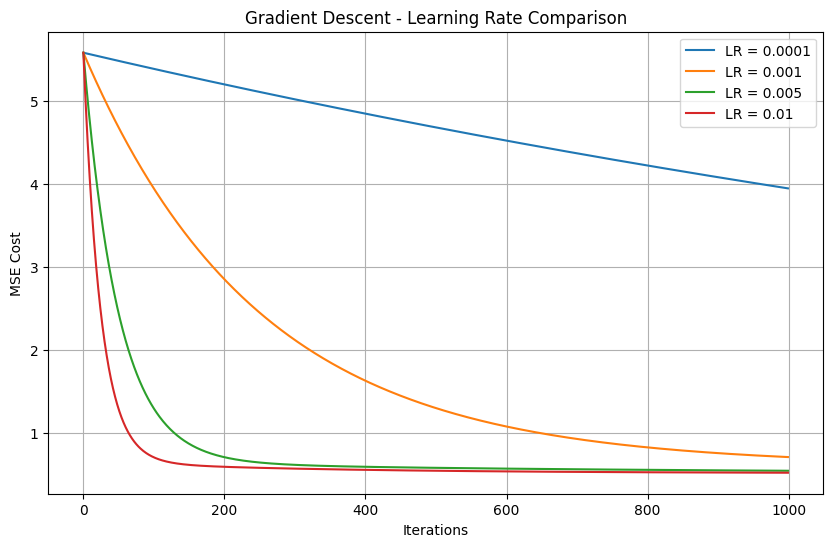

In [43]:
plt.figure(figsize=(10, 6))

for lr, cost_history in results.items():
    plt.plot(cost_history, label=f"LR = {lr}")

plt.xlabel("Iterations")
plt.ylabel("MSE Cost")
plt.title("Gradient Descent - Learning Rate Comparison")
plt.legend()
plt.grid(True)

plt.show()

In [44]:
learning_rate = 0.01
iterations = 1000

theta = np.zeros(X_train.shape[1])

optimized_theta, cost_history = gradient_descent(
    X_train,
    y_train,
    theta,
    learning_rate,
    iterations
)

In [45]:
y_pred = hypothesis(X_test, optimized_theta)

test_mse = compute_cost(y_test, y_pred)

ss_res = np.sum((y_test - y_pred) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

r2 = 1 - (ss_res / ss_tot)

print("NumPy Linear Regression")
print("Test MSE:", test_mse)
print("Test R2 Score:", r2)

NumPy Linear Regression
Test MSE: 0.5521454566839193
Test R2 Score: 0.5936604548357833


In [46]:
from sklearn.linear_model import LinearRegression

sk_model = LinearRegression()

sk_model.fit(X_train[:, 1:], y_train)

sk_predictions = sk_model.predict(X_test[:, 1:])

sk_mse = np.mean((y_test - sk_predictions) ** 2)

ss_res = np.sum((y_test - sk_predictions) ** 2)
ss_tot = np.sum((y_test - np.mean(y_test)) ** 2)

sk_r2 = 1 - (ss_res / ss_tot)

print("Scikit-learn Linear Regression")
print("Test MSE:", sk_mse)
print("Test R2 Score:", sk_r2)

Scikit-learn Linear Regression
Test MSE: 0.552233239936362
Test R2 Score: 0.5935958526436639


In [47]:
comparison = pd.DataFrame({
    "NumPy": optimized_theta[1:],
    "Scikit-learn": sk_model.coef_
}, index=housing.feature_names)

print(comparison)

print("\nIntercept Comparison")
print("NumPy:", optimized_theta[0])
print("Scikit-learn:", sk_model.intercept_)

print("\nR2 Score Comparison")
print("NumPy:", r2)
print("Scikit-learn:", sk_r2)

               NumPy  Scikit-learn
MedInc      0.838608      0.828723
HouseAge    0.152160      0.123116
AveRooms   -0.237999     -0.270688
AveBedrms   0.277097      0.328591
Population  0.012117      0.002136
AveOccup   -0.032097     -0.028101
Latitude   -0.697690     -0.930180
Longitude  -0.661383     -0.895055

Intercept Comparison
NumPy: 2.063476805176351
Scikit-learn: 2.0634768086491158

R2 Score Comparison
NumPy: 0.5936604548357833
Scikit-learn: 0.5935958526436639
